<a href="https://colab.research.google.com/github/Ch3ddarr/dsb_capstone/blob/main/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First it's time to start exploring my data. I was able to find a dataset online that has a lot of details about trafic. This is synthetic data.



1. No.	Name	Type 	Description
2. srcip	nominal	Source IP address
3. sport	integer	Source port number
4. dstip	nominal	Destination IP address
5. dsport	integer	Destination port number
6. proto	nominal	Transaction protocol
7. state	nominal	Indicates to the state and its dependent protocol, e.g. ACC, CLO, CON, ECO, ECR, FIN, INT, MAS, PAR, REQ, RST, TST, TXD, URH, URN, and (-) (if not used state)
8.	dur	Float	Record total duration
9.	sbytes	Integer	Source to destination transaction bytes
10.	dbytes	Integer	Destination to source transaction bytes
11.	sttl	Integer	Source to destination time to live value
12.	dttl	Integer	Destination to source time to live value
13.	sloss	Integer	Source packets retransmitted or dropped
14.	dloss	Integer	Destination packets retransmitted or dropped
15.	service	nominal	http, ftp, smtp, ssh, dns, ftp-data ,irc  and (-) if not much used service
16.	Sload	Float	Source bits per second
17.	Dload	Float	Destination bits per second
18.	Spkts	integer	Source to destination packet count
19.	Dpkts	integer	Destination to source packet count
20.	swin	integer	Source TCP window advertisement value
21.	dwin	integer	Destination TCP window advertisement value
22.	stcpb	integer	Source TCP base sequence number
23.	dtcpb	integer	Destination TCP base sequence number
24.	smeansz	integer	Mean of the ?ow packet size transmitted by the src
25.	dmeansz	integer	Mean of the ?ow packet size transmitted by the dst
26.	trans_depth	integer	Represents the pipelined depth into the connection of http request/response transaction
27.	res_bdy_len	integer	Actual uncompressed content size of the data transferred from the server’s http service.
28.	Sjit	Float	Source jitter (mSec)
29.	Djit	Float	Destination jitter (mSec)
30.	Stime	Timestamp	record start time
31.	Ltime	Timestamp	record last time
32.	Sintpkt	Float	Source interpacket arrival time (mSec)
33.	Dintpkt	Float	Destination interpacket arrival time (mSec)
34.	tcprtt	Float	TCP connection setup round-trip time, the sum of ’synack’ and ’ackdat’.
35.	synack	Float	TCP connection setup time, the time between the SYN and the SYN_ACK packets.
36.	ackdat	Float	TCP connection setup time, the time between the SYN_ACK and the ACK packets.
37.	is_sm_ips_ports	Binary	If source (1) and destination (3)IP addresses equal and port numbers (2)(4)  equal then, this variable takes value 1 else 0
38.	ct_state_ttl	Integer	No. for each state (6) according to specific range of values for source/destination time to live (10) (11).
39.	ct_flw_http_mthd	Integer	No. of flows that has methods such as Get and Post in http service.
40.	is_ftp_login	Binary	If the ftp session is accessed by user and password then 1 else 0.
41.	ct_ftp_cmd	integer	No of flows that has a command in ftp session.
42.	ct_srv_src	integer	No. of connections that contain the same service (14) and source address (1) in 100 connections according to the last time (26).
43.	ct_srv_dst	integer	No. of connections that contain the same service (14) and destination address (3) in 100 connections according to the last time (26).
44.	ct_dst_ltm	integer	No. of connections of the same destination address (3) in 100 connections according to the last time (26).
45.	ct_src_ ltm	integer	No. of connections of the same source address (1) in 100 connections according to the last time (26).
46.	ct_src_dport_ltm	integer	No of connections of the same source address (1) and the destination port (4) in 100 connections according to the last time (26).
47.	ct_dst_sport_ltm	integer	No of connections of the same destination address (3) and the source port (2) in 100 connections according to the last time (26).
48.	ct_dst_src_ltm	integer	No of connections of the same source (1) and the destination (3) address in in 100 connections according to the last time (26).
49.	attack_cat	nominal	The name of each attack category. In this data set , nine categories e.g. Fuzzers, Analysis, Backdoors, DoS Exploits, Generic, Reconnaissance, Shellcode and Worms
50.	Label	binary	0 for normal and 1 for attack records





In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [3]:
train = pd.read_csv("/content/UNSW_NB15_training-set.csv")
#test = pd.read_csv("/content/UNSW_NB15_testing-set.csv")

In [4]:
# Here we take a look at the dataset
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

In [5]:
train.shape

(175341, 45)

In [6]:
train.head(1).T

,0
id,1
dur,0.121478
proto,tcp
service,-
state,FIN
spkts,6
dpkts,4
sbytes,258
dbytes,172
rate,74.08749


No missing values in the dataset, which is good

<Axes: xlabel='attack_cat'>

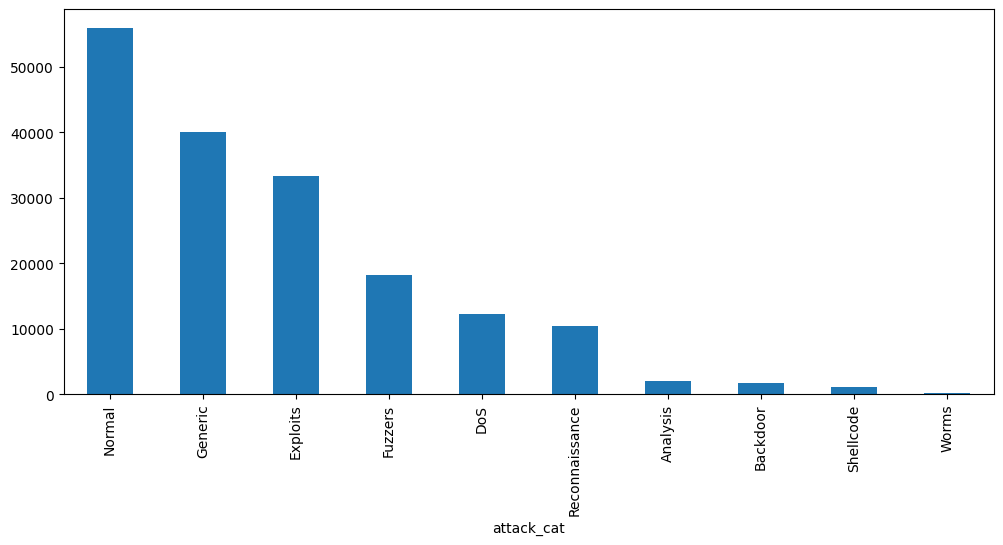

In [19]:
# We can see that the majority of the attacks categories are exploits, fuzzers and DoS,
# while Reconnaissance is also one of the bigger groups. Other than that we see
train['attack_cat'].value_counts().plot(kind='bar', figsize=(12,5)) #.hist(figsize=(15,10), bins=25)

<Axes: xlabel='attack_cat'>

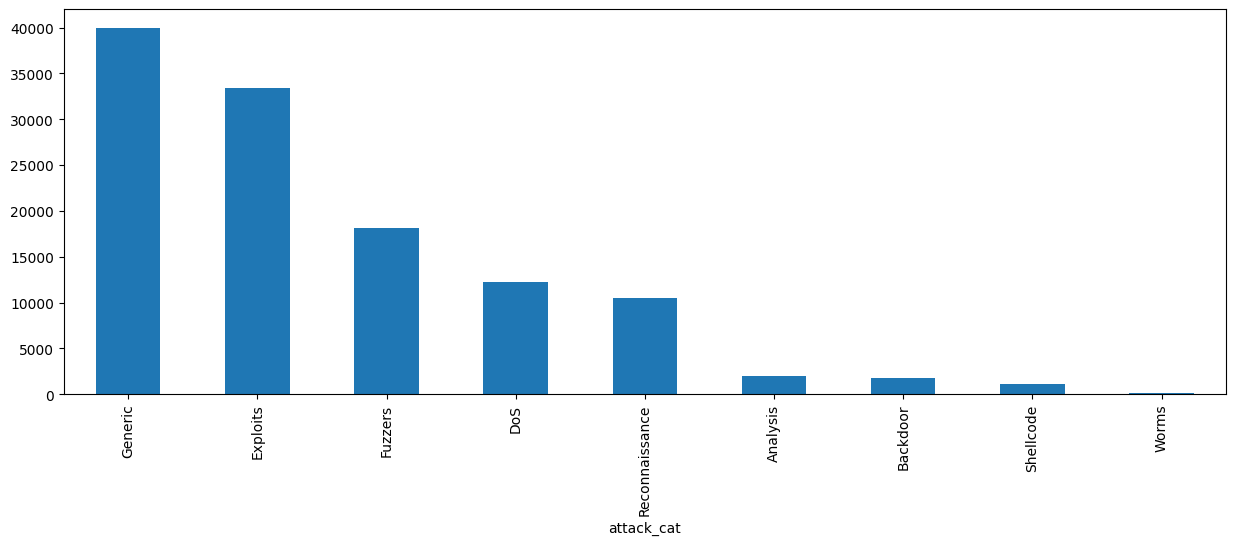

In [21]:
# Plotting the attacks that are labeled as malicious
train[train['label']==1]['attack_cat'].value_counts().plot(kind='bar', figsize=(15,5))

In [20]:
# This is the number of malicious network traffic
att_traff = train[(train['label']==1)]['id'].count()
att_traff

np.int64(119341)

In [22]:
# Looking for the number of normal traffic
norm_traff = train.shape[0] - att_traff
norm_traff

np.int64(56000)

In [23]:
# Most of the attacks happen on UDP and TCP port, which is what I expected
train[train['label']==1]['proto'].value_counts()

,count
proto,
udp,49361
tcp,40825
unas,12084
ospf,2531
sctp,1150
...,...
argus,98
bbn-rcc,98
hmp,98


In [24]:
train.groupby('label')['dur'].mean()

,dur
label,
0,1.017177
1,1.519969


<Axes: xlabel='label'>

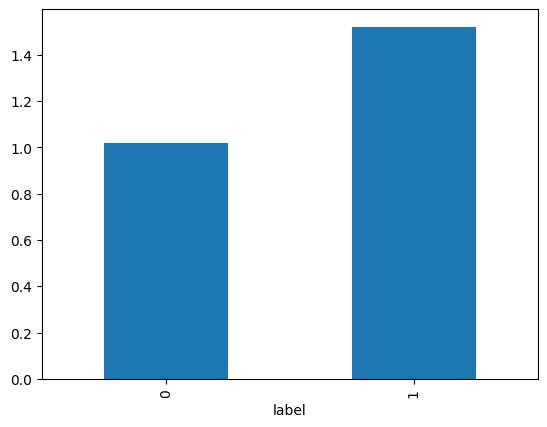

In [25]:
train.groupby('label')['dur'].mean().plot(kind='bar')

In [27]:
# Data can be misleading, we can see, according to median values, that actually non-malicious traffic goes for longer than malicious traffic
train.groupby('label')['dur'].describe() #.agg(['mean', 'median'])

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,56000.0,1.017177,4.859242,0.0,0.001718,0.038602,0.639830,59.999989
1,119341.0,1.519969,7.109044,0.0,0.000006,0.000009,0.679699,59.999046


In [28]:
# attack traffic has generally more sending bytes than non-malicious ones
# source ttl values mean suggest that most of the malicious traffic is coming from CISCO IOS/NX OS

train[train['label']==1].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
id,119341.0,1.128843e+05,3.745315e+04,47912.0,79711.00,115504.00,1.455060e+05,1.753410e+05
dur,119341.0,1.520000e+00,7.110000e+00,0.0,0.00,0.00,6.800000e-01,6.000000e+01
spkts,119341.0,1.541000e+01,1.609800e+02,1.0,2.00,2.00,1.000000e+01,9.616000e+03
dpkts,119341.0,1.001000e+01,1.111800e+02,0.0,0.00,0.00,8.000000e+00,1.097400e+04
sbytes,119341.0,1.106866e+04,2.116586e+05,60.0,114.00,200.00,8.480000e+02,1.296523e+07
dbytes,119341.0,7.364460e+03,1.447241e+05,0.0,0.00,0.00,3.540000e+02,1.465555e+07
rate,119341.0,1.336997e+05,1.828434e+05,0.0,34.08,111111.11,1.666667e+05,1.000000e+06
sttl,119341.0,2.284000e+02,6.558000e+01,0.0,254.00,254.00,2.540000e+02,2.550000e+02
dttl,119341.0,8.680000e+01,1.194300e+02,0.0,0.00,0.00,2.520000e+02,2.520000e+02
sload,119341.0,9.704916e+07,1.990572e+08,0.0,13776.25,50666664.00,1.000000e+08,5.988000e+09


In [29]:
train[train['label']==0].describe().round(2)

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,5.600000e+04,...,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,56000.00,56000.0
mean,33939.20,1.02,30.73,38.06,4105.70,31049.46,13799.31,75.45,64.28,2.317070e+07,...,1.79,1.19,3.87,0.02,0.02,0.12,4.06,5.52,0.05,0.0
std,28120.94,4.86,57.34,105.77,11348.05,139991.25,68031.39,89.96,86.57,1.514274e+08,...,2.73,2.01,5.39,0.13,0.13,0.50,3.92,5.78,0.22,0.0
min,1.00,0.00,1.00,0.00,28.00,0.00,0.00,0.00,0.00,0.000000e+00,...,1.00,1.00,1.00,0.00,0.00,0.00,1.00,1.00,0.00,0.0
25%,14000.75,0.00,4.00,2.00,424.00,178.00,30.73,31.00,29.00,1.235262e+04,...,1.00,1.00,1.00,0.00,0.00,0.00,2.00,2.00,0.00,0.0
50%,28000.50,0.04,12.00,10.00,1470.00,1112.00,1382.26,31.00,29.00,4.313277e+05,...,1.00,1.00,2.00,0.00,0.00,0.00,3.00,4.00,0.00,0.0
75%,42000.25,0.64,40.00,40.00,3401.50,10168.00,3177.69,31.00,29.00,8.273671e+05,...,2.00,1.00,4.00,0.00,0.00,0.00,5.00,7.00,0.00,0.0
max,115964.00,60.00,656.00,1716.00,338718.00,2249492.00,1000000.00,255.00,254.00,5.344000e+09,...,46.00,46.00,63.00,2.00,2.00,12.00,47.00,62.00,1.00,0.0


In [30]:
train['label'].value_counts()

,count
label,
1,119341
0,56000


In [31]:
train.groupby(['attack_cat', 'label']).size()

,,0
attack_cat,label,
Analysis,1,2000
Backdoor,1,1746
DoS,1,12264
Exploits,1,33393
Fuzzers,1,18184
Generic,1,40000
Normal,0,56000
Reconnaissance,1,10491
Shellcode,1,1133


In [32]:
pd.crosstab(train['attack_cat'], train['label'])

label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


In [33]:
attack_rate = train.groupby('proto')['label'].agg(['count', 'mean']).sort_values('count', ascending=False)
attack_rate.head(10)

,count,mean
proto,,
tcp,79946,0.510657
udp,63283,0.780004
unas,12084,1.000000
arp,2859,0.000000
ospf,2595,0.975337
sctp,1150,1.000000
any,300,1.000000
gre,225,1.000000
swipe,201,1.000000


**Let's get into modelling**

In [34]:
# Dropping the object variables
X = train.drop(columns = ['id', 'label', 'attack_cat'])
y = train['label']

In [35]:
# I have only 3 columns that are object variables that I will turn into
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 42 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   dur                175341 non-null  float64
 1   proto              175341 non-null  object 
 2   service            175341 non-null  object 
 3   state              175341 non-null  object 
 4   spkts              175341 non-null  int64  
 5   dpkts              175341 non-null  int64  
 6   sbytes             175341 non-null  int64  
 7   dbytes             175341 non-null  int64  
 8   rate               175341 non-null  float64
 9   sttl               175341 non-null  int64  
 10  dttl               175341 non-null  int64  
 11  sload              175341 non-null  float64
 12  dload              175341 non-null  float64
 13  sloss              175341 non-null  int64  
 14  dloss              175341 non-null  int64  
 15  sinpkt             175341 non-null  float64
 16  di

In [ ]:
### I will skip this for now, because this makes too many columns
X = pd.get_dummies(X, columns=['proto', 'service', 'state'], drop_first=True, dtype=int)

In [36]:
X.shape

(175341, 42)

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)


In [40]:
categorical_cols = ['proto', 'service', 'state']
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [41]:
preprocessing = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_cols)
        ]
    )

In [ ]:
# My baseline model will be the one that says "Every traffic that comes in is
# an attack", so looking at that we can say that this model is 68.1% accurate

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessing),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [47]:
lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['dur', 'spkts', 'dpkts',
                                                   'sbytes', 'dbytes', 'rate',
                                                   'sttl', 'dttl', 'sload',
                                                   'dload', 'sloss', 'dloss',
                                                   'sinpkt', 'dinpkt', 'sjit',
                                                   'djit', 'swin', 'stcpb',
                                                   'dtcpb', 'dwin', 'tcprtt',
                                                   'synack', 'ackdat', 'smean',
                                                   'dmean', 'trans_depth',
                                                   'response_body_len',
                                                   'ct_srv_src', 'ct_state_ttl',
                                                   'ct_dst_ltm', ...]),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['proto', 'service',
                                                   'state'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [53]:
y_pred_lr = lr_pipeline.predict(X_test)
y_pred_lr[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [54]:
y_proba_lr = lr_pipeline.predict_proba(X_test)[:, 1]
print(y_proba_lr[:10])

[0.98820602 0.99965675 0.86715232 0.95295784 0.99955665 0.95373132
 0.72870769 0.99978646 0.99813566 0.76925719]


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score
)

accuracy_score(y_test, y_pred_lr)

0.936354044882945